# Spread e FRAs - Histórico com Vértices Fixos

In [1]:
import pandas as pd
import matplotlib.pyplot as plot
import matplotlib.dates as mdates
import seaborn as sns
import time
from datetime import datetime, timedelta, date
import teradata

start = time.time() 
system = "TERADBAWS.sicredi.net"
user = "P_USR_DL_GESTAO_RECURSOS"
passw = "JAW0b71329aadade35365afc6X"
udaExec = teradata.UdaExec (appName="TESTE", version="1.0", logConsole=False)
session = udaExec.connect(method="odbc", system=system,
      username=user, password=passw, Authentication="TDNEGO");

lista  = ['.5x.75','.5x1','.75x1.5','.5x1.5','1.5x4.5','2x7','5x9','7x9','4x9','1x2','1x3','1x4','2x4','2x5','3x5','5x7','3x7','4x8','8x9','9x10', '7x9','6x7','6x8','8x10','5x10','5x8']       
lista_string = "','".join(map(str,lista))

lista_reduzida  = ['4x6','1x3','2x4','3x4','1x2','1.5x4.5']       
lista_string = "','".join(map(str,lista_reduzida))


Select = """
  SELECT DT
, FRA
, FWD_AB
, SPREAD_AB
, AVG(FWD_AB) OVER (PARTITION BY FRA ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) AS MEDIA_6M
, AVG(FWD_AB) OVER (PARTITION BY FRA ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) + 2*(STDDEV_SAMP(FWD_AB) OVER (PARTITION BY FRA ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW)) as LIM_SUP_6M
, AVG(FWD_AB) OVER (PARTITION BY FRA ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) - 2*(STDDEV_SAMP(FWD_AB) OVER (PARTITION BY FRA ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW)) as LIM_INF_6M
, MIN(FWD_AB) OVER (PARTITION BY FRA ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) AS MINIMO_6M
, MAX(FWD_AB) OVER (PARTITION BY FRA ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) AS MAXIMO_6M
, STDDEV_SAMP(FWD_AB) OVER (PARTITION BY FRA ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) AS DEVPAD_AM_6M
, CDI
, DI_252
, FL_FIM_MES

FROM 
(SELECT DI_B.DATA as DT
, to_char(ROUND(CAST(DI_A.VERTICE AS FLOAT)/252,2))  || 'x' || TO_CHAR(ROUND(CAST(DI_B.VERTICE AS FLOAT)/252,2)) AS FRA
, DI_A.VERTICE AS CONTRATO_A, DI_B.VERTICE AS CONTRATO_B
, DI_A.TAXA AS TAXA_A, DI_B.TAXA AS TAXA_B
, ((1+DI_B.TAXA)**(CAST(DI_B.VERTICE AS FLOAT)/(DI_B.VERTICE-DI_A.VERTICE))/(1+DI_A.TAXA)**(CAST(DI_A.VERTICE AS FLOAT)/(DI_B.VERTICE-DI_A.VERTICE)))-1 AS FWD_AB
,  (DI_B.TAXA - DI_A.TAXA) as SPREAD_AB
, ((IDX.VALOR/3000+1)**252.000000-1)*100 AS CDI
, DI_C.TAXA*100 AS DI_252
, NVL(DU.FL_FIM_MES, DU.FL_D1) AS FL_FIM_MES
FROM DL_GESTAO_RECURSOS.CURVA DI_B
LEFT JOIN DL_GESTAO_RECURSOS.CURVA DI_A ON DI_A.DATA = DI_B.DATA AND DI_A.VERTICE < DI_B.VERTICE
LEFT JOIN DL_GESTAO_RECURSOS.CURVA DI_C ON DI_C.DATA = DI_B.DATA AND DI_C.VERTICE = 504
LEFT JOIN DL_GESTAO_RECURSOS.IDX_INDEX IDX ON IDX.DATA = DI_B.DATA AND IDX.CODINDEX = 'CDI'
LEFT JOIN dl_Gestao_recursos.vw_du DU ON DU.DT = DI_B.DATA  AND (DU.FL_FIM_MES = 1 or du.fl_d1 = 1)
WHERE DI_B.VERTICE IN ('126','189','252','315','378','441','504','567','630','756','882','1008','1134','1260','1512','1764','2016','2268','2520')
and DI_A.VERTICE IN ('126','189','252','315','378','441','504','567','630','756','882','1008','1134','1260','1512','1764','2016','2268','2520')
and DI_C.VERTICE IN ('126','189','252','315','378','441','504','567','630','756','882','1008','1134','1260','1512','1764','2016','2268','2520')) VW
WHERE VW.DT >= '2024-01-01'
AND FRA IN ('""" + lista_string +""" ') """


df = pd.read_sql(Select, session) 
df.DT = pd.to_datetime(df.DT, format='%Y-%m-%d') 
pd.set_option('mode.chained_assignment', None)




C:\Users\andre_trierveiler\AppData\Local\Temp\ipykernel_31988\2318636946.py:61: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(Select, session)


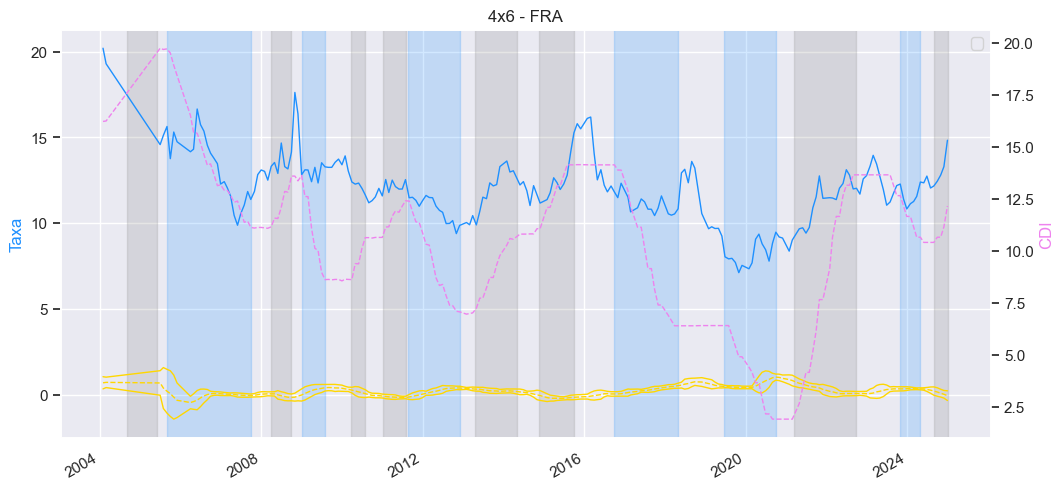

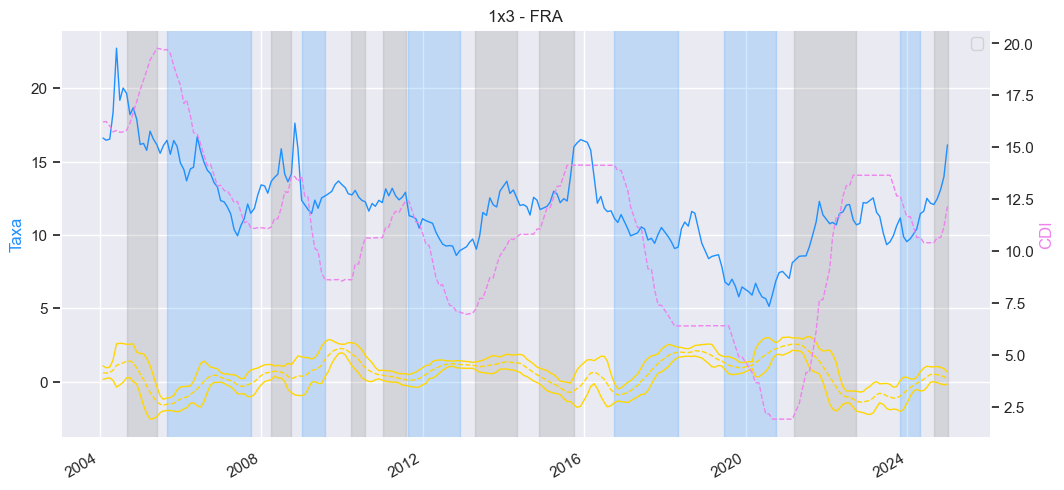

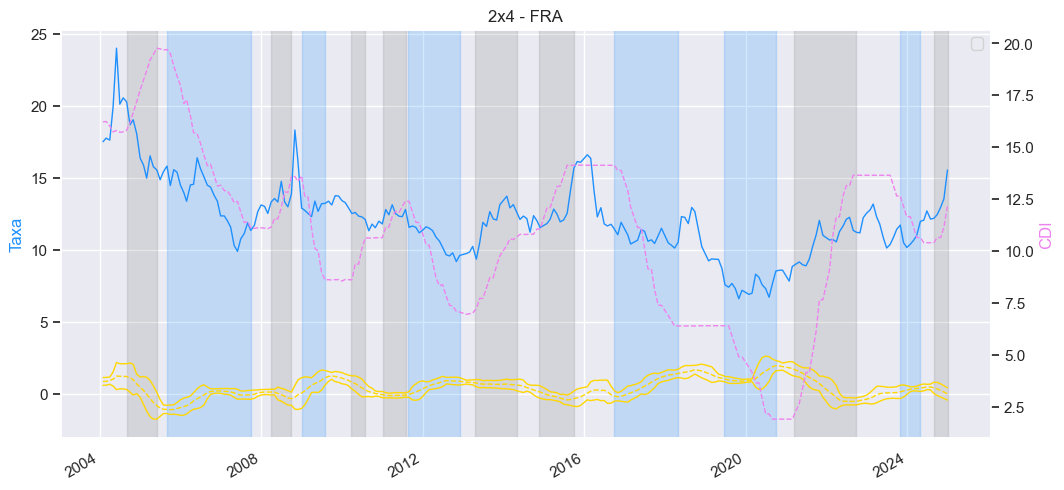

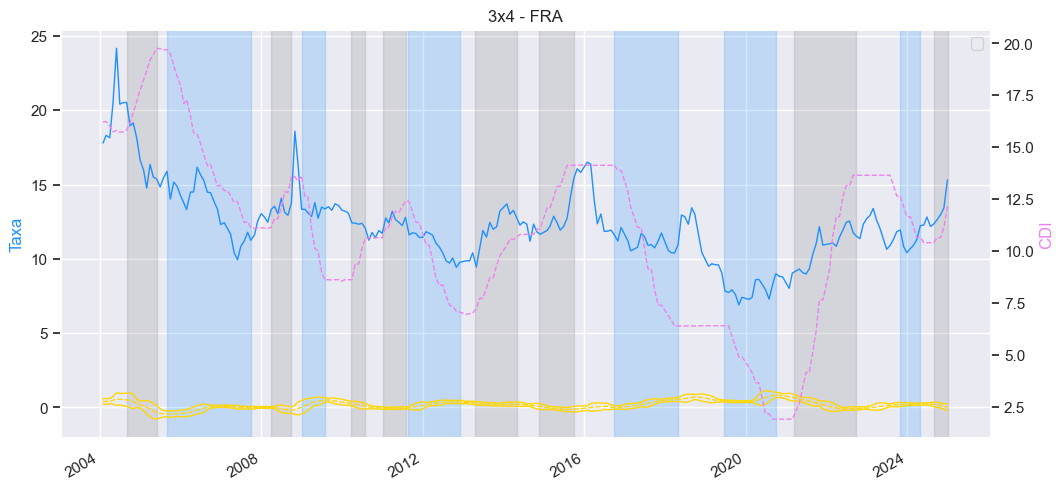

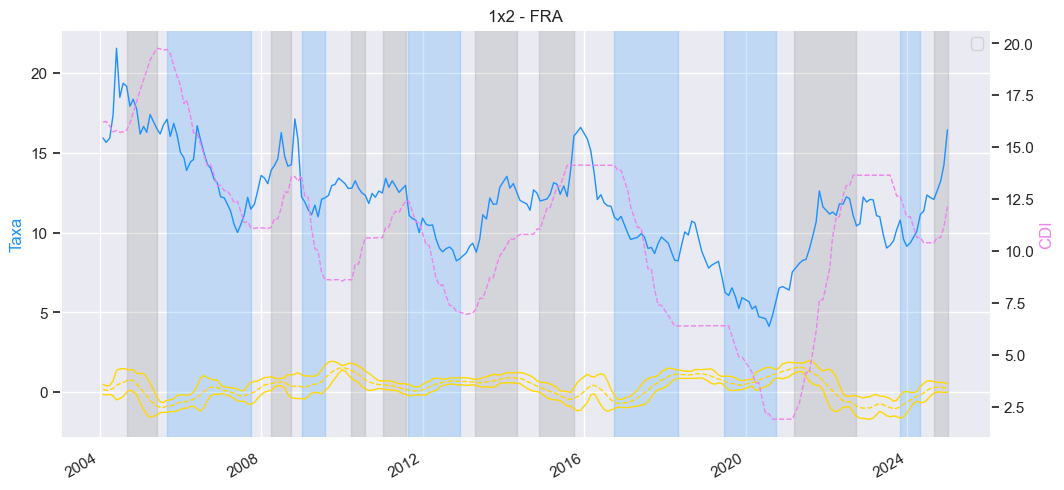

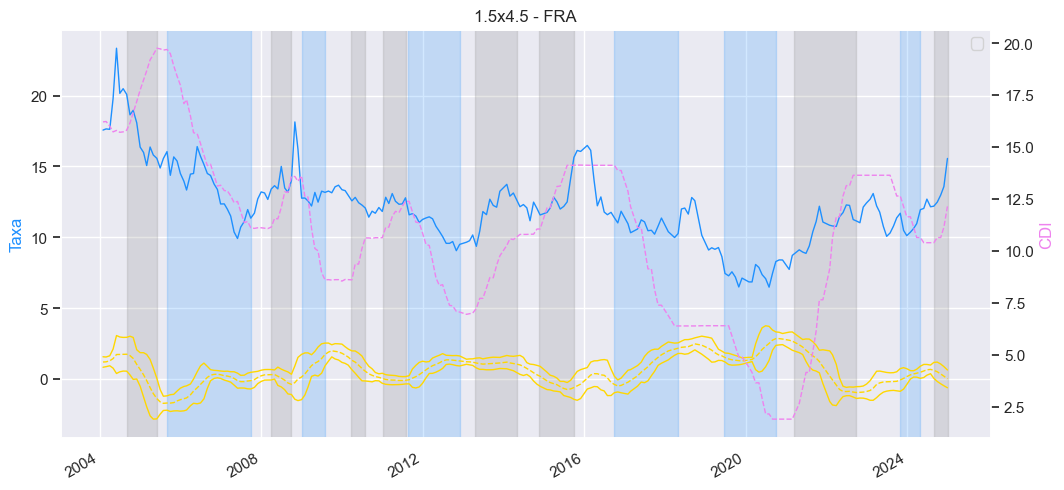

In [7]:
for x in lista_reduzida:   
        df_grafico = df[df.FRA == x]    
        df_grafico = df_grafico.sort_values(by=['DT'])
        fra_nome = x
        df_grafico = df_grafico[df_grafico.FL_FIM_MES == 1]
        #df_grafico = df_grafico[df_grafico.DT >= datetime(2007,7,30)]

        sns.set(style="darkgrid", palette="Set2")
        plot.rcParams['figure.figsize'] = (12,6)

        fig, ax = plot.subplots()
        ax2 = ax.twinx()
        ax.plot(df_grafico.DT,df_grafico['FWD_AB']*100, marker = '', color='dodgerblue',linestyle='-',linewidth=1,)
        ax.plot(df_grafico.DT,df_grafico['MEDIA_6M']*100, marker='', color='gold',linestyle='--',linewidth=1)
        ax.plot(df_grafico.DT,df_grafico['LIM_INF_6M']*100, marker='', color='gold',linestyle='-',linewidth=1)
        ax.plot(df_grafico.DT,df_grafico['LIM_SUP_6M']*100, marker='', color='gold',linestyle='-',linewidth=1)
        ax.axvspan(datetime(2004,8,30),datetime(2005,5,30), color="grey", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2008,3,31),datetime(2008,9,30), color="grey", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2010,3,19),datetime(2010,7,30), color="grey", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2011,1,2),    datetime(2011,7,30), color="grey", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2013,4,18),    datetime(2014,4,30), color="grey", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2014,11,15), datetime(2015,9,30), color="grey", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2005,8,30),datetime(2007,9,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2009,1,5),datetime(2009,7,31), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2011,8,20),datetime(2012,11,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2016,9,30), datetime(2018,4,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2019,6,22),datetime(2020,9,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2021,3,16),    datetime(2022,9,30), color="grey", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2023,11,1),datetime(2024,4,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2024,9,1),datetime(2025,1,1), color="grey", alpha=0.2,ymin=0, ymax=100)
        ax2.plot(df_grafico.DT,df_grafico['CDI'], marker='', color='violet',linestyle='--',linewidth=1)
        #ax2.plot(df_grafico.DT,df_grafico['DI_252'], marker='', color='violet',linestyle='--',linewidth=1)
        ax.set_ylabel('Taxa', color='dodgerblue')
        ax2.set_ylabel('CDI', color='violet',labelpad=None)
        ax2.grid(visible=False)
        ax.legend()

        #ax.plot_date(fly_grafico.DT,fly_grafico['SUP_MDL']*10000, marker='', color='violet',linestyle='-',linewidth=1)
        #ax.plot_date(fly_grafico.DT,fly_grafico['INF_MDL']*10000, marker='', color='violet',linestyle='-',linewidth=1)
        plot.title(fra_nome + " - FRA")
        #plot.ylabel('Taxa')
        plot.xlabel('Data')
        fig.autofmt_xdate()
        ax.fmt_xdata = mdates.DateFormatter('%Y-%m')
        plot.show()
        #plt.savefig('FLY.png', transparent = True)
        #fly_grafico.set_index('DT',inplace=True)
        
        
        
 

C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating

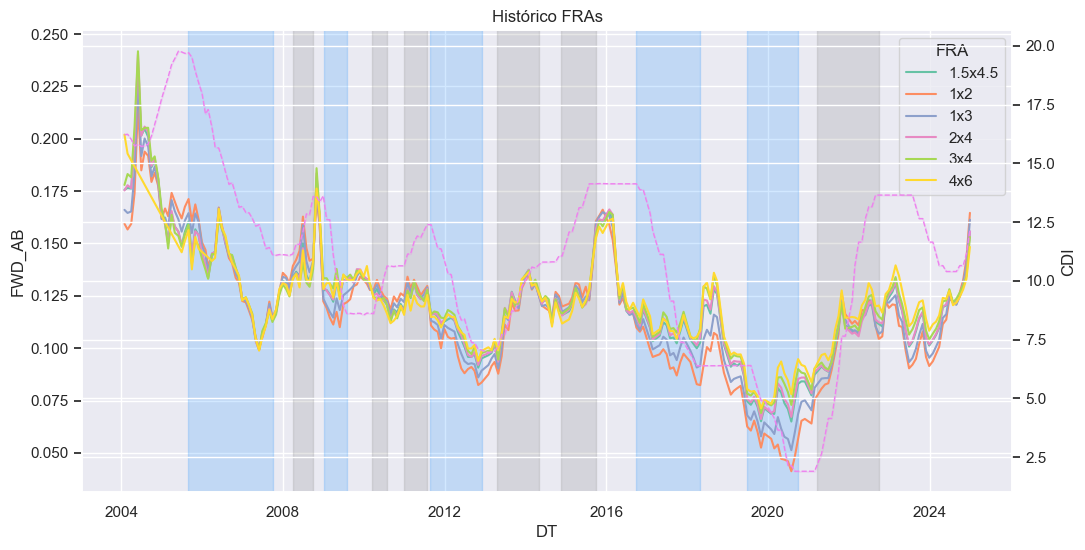

In [3]:

df = df.sort_values(by=['DT','FRA'])
df_grafico = df[df['FRA'].isin(lista_reduzida)]
df_grafico = df_grafico[df_grafico.FL_FIM_MES == 1]
#df_grafico = df_grafico[df_grafico.DT >= datetime(2008,12,30)]

sns.set(style="darkgrid", palette="Set2")
ax1 = sns.lineplot(x='DT', y='FWD_AB', data=df_grafico, hue='FRA')
ax2 = ax1.twinx()
#ax1.axvspan(datetime(2004,8,30),datetime(2005,5,30), color="grey", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2008,3,31),datetime(2008,9,30), color="grey", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2010,3,19),datetime(2010,7,30), color="grey", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2011,1,2),    datetime(2011,7,30), color="grey", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2013,4,18),    datetime(2014,4,30), color="grey", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2014,11,15), datetime(2015,9,30), color="grey", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2021,3,16),    datetime(2022,9,30), color="grey", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2005,8,30),datetime(2007,9,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2009,1,5),datetime(2009,7,31), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2011,8,20),datetime(2012,11,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2016,9,30), datetime(2018,4,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2019,6,22),datetime(2020,9,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
ax.axvspan(datetime(2021,3,16),    datetime(2022,9,30), color="grey", alpha=0.2,ymin=0, ymax=100)
ax.axvspan(datetime(2023,11,1),datetime(2024,4,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
ax.axvspan(datetime(2024,9,1),datetime(2025,1,1), color="grey", alpha=0.2,ymin=0, ymax=100)
ax2 = sns.lineplot(x='DT', y='CDI', data=df_grafico, color='violet',linestyle='--',linewidth=1)
ax1.set(title='Histórico FRAs')
plot.show()       

In [4]:
Select = """
  SELECT DT
, FRA
, FWD_AB
, SPREAD_AB
, AVG(SPREAD_AB) OVER (PARTITION BY FRA ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) AS MEDIA_6M
, AVG(SPREAD_AB) OVER (PARTITION BY FRA ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) + 2*(STDDEV_SAMP(SPREAD_AB) OVER (PARTITION BY FRA ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW)) as LIM_SUP_6M
, AVG(SPREAD_AB) OVER (PARTITION BY FRA ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) - 2*(STDDEV_SAMP(SPREAD_AB) OVER (PARTITION BY FRA ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW)) as LIM_INF_6M
, MIN(SPREAD_AB) OVER (PARTITION BY FRA ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) AS MINIMO_6M
, MAX(SPREAD_AB) OVER (PARTITION BY FRA ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) AS MAXIMO_6M
, STDDEV_SAMP(SPREAD_AB) OVER (PARTITION BY FRA ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) AS DEVPAD_AM_6M
, CDI
, DI_252
, FL_FIM_MES

FROM 
(SELECT DI_B.DATA as DT
, to_char(ROUND(CAST(DI_A.VERTICE AS FLOAT)/252,2))  || 'x' || TO_CHAR(ROUND(CAST(DI_B.VERTICE AS FLOAT)/252,2)) AS FRA
, DI_A.VERTICE AS CONTRATO_A, DI_B.VERTICE AS CONTRATO_B
, DI_A.TAXA AS TAXA_A, DI_B.TAXA AS TAXA_B
, ((1+DI_B.TAXA)**(CAST(DI_B.VERTICE AS FLOAT)/(DI_B.VERTICE-DI_A.VERTICE))/(1+DI_A.TAXA)**(CAST(DI_A.VERTICE AS FLOAT)/(DI_B.VERTICE-DI_A.VERTICE)))-1 AS FWD_AB
,  (DI_B.TAXA - DI_A.TAXA) as SPREAD_AB
, ((IDX.VALOR/3000+1)**252.000000-1)*100 AS CDI
, DI_C.TAXA*100 AS DI_252
, NVL(DU.FL_FIM_MES, DU.FL_D1) AS FL_FIM_MES
FROM DL_GESTAO_RECURSOS.CURVA DI_B
LEFT JOIN DL_GESTAO_RECURSOS.CURVA DI_A ON DI_A.DATA = DI_B.DATA AND DI_A.VERTICE < DI_B.VERTICE
LEFT JOIN DL_GESTAO_RECURSOS.CURVA DI_C ON DI_C.DATA = DI_B.DATA AND DI_C.VERTICE = 504
LEFT JOIN DL_GESTAO_RECURSOS.IDX_INDEX IDX ON IDX.DATA = DI_B.DATA AND IDX.CODINDEX = 'CDI'
LEFT JOIN dl_Gestao_recursos.vw_du DU ON DU.DT = DI_B.DATA  AND (DU.FL_FIM_MES = 1 or du.fl_d1 = 1)
WHERE DI_B.VERTICE IN ('126','189','252','315','378','441','504','567','630','756','882','1008','1134','1260','1512','1764','2016','2268','2520')
and DI_A.VERTICE IN ('126','189','252','315','378','441','504','567','630','756','882','1008','1134','1260','1512','1764','2016','2268','2520')
and DI_C.VERTICE IN ('126','189','252','315','378','441','504','567','630','756','882','1008','1134','1260','1512','1764','2016','2268','2520')) VW
WHERE VW.DT >= '2004-01-01'
AND FRA IN ('""" + lista_string +""" ') """


df = pd.read_sql(Select, session) 
df.DT = pd.to_datetime(df.DT, format='%Y-%m-%d') 
pd.set_option('mode.chained_assignment', None)




C:\Users\andre_trierveiler\AppData\Local\Temp\ipykernel_31988\1403799995.py:38: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(Select, session)


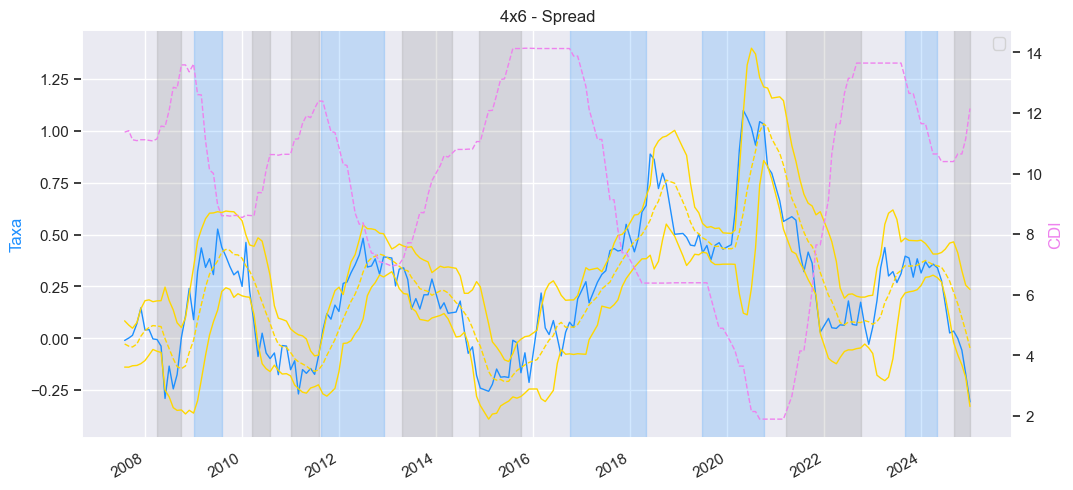

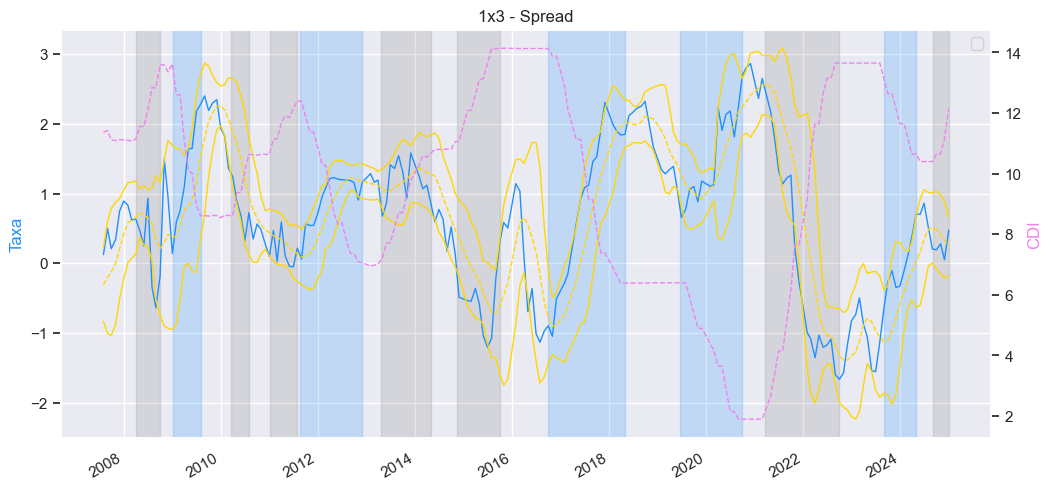

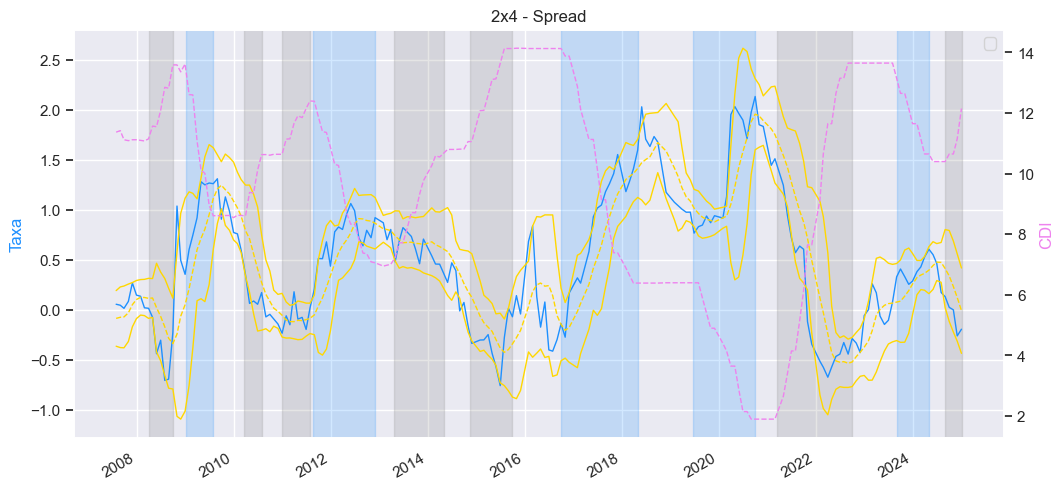

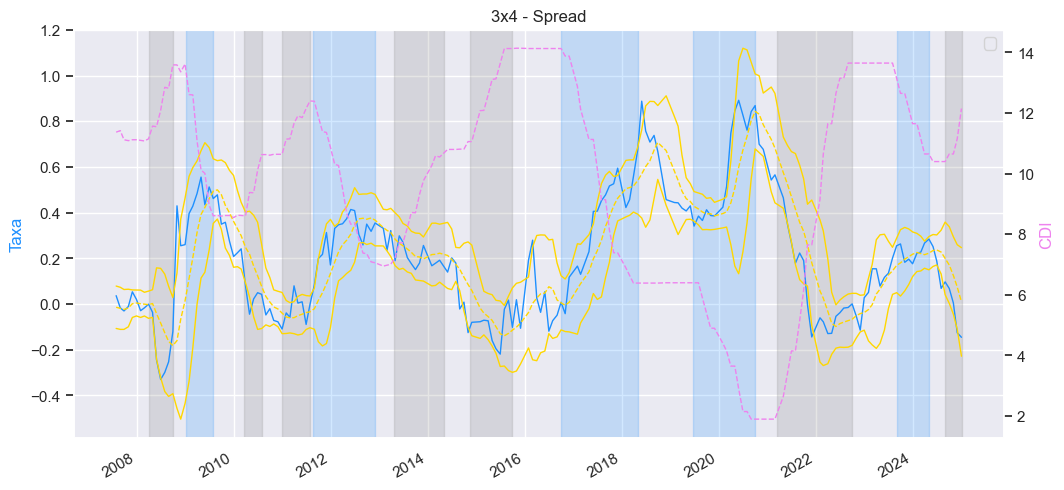

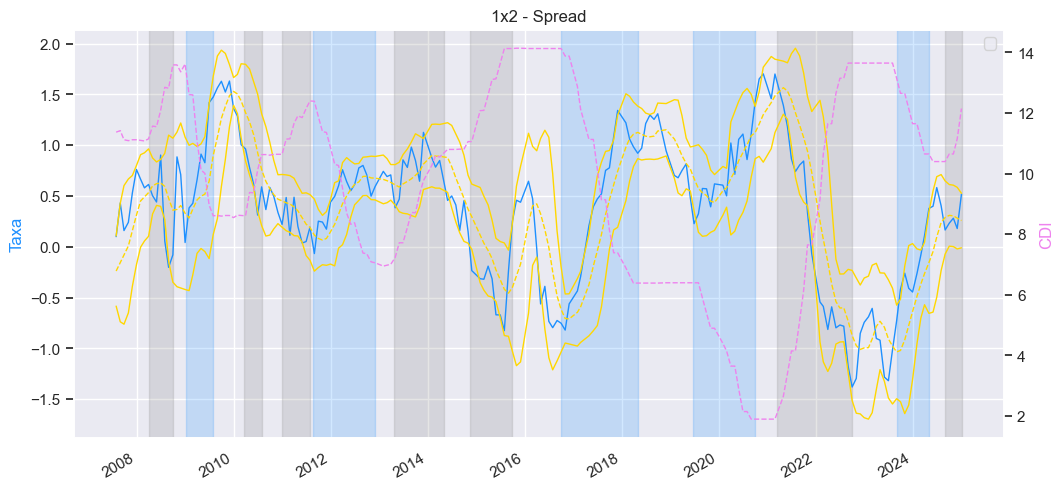

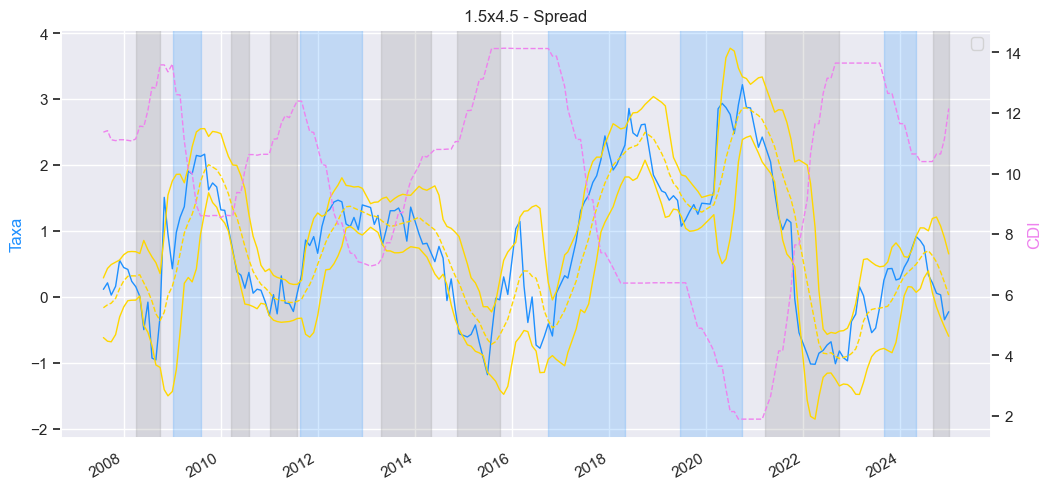

In [10]:
for x in lista_reduzida:   
        df_grafico = df[df.FRA == x]    
        df_grafico = df_grafico.sort_values(by=['DT'])
        fra_nome = x
        df_grafico = df_grafico[df_grafico.FL_FIM_MES == 1]
        df_grafico = df_grafico[df_grafico.DT >= datetime(2007,6,30)]

        sns.set(style="darkgrid", palette="Set2")
        plot.rcParams['figure.figsize'] = (12,6)

        fig, ax = plot.subplots()
        ax2 = ax.twinx()
        ax.plot(df_grafico.DT,df_grafico['SPREAD_AB']*100, marker = '', color='dodgerblue',linestyle='-',linewidth=1,)
        ax.plot(df_grafico.DT,df_grafico['MEDIA_6M']*100, marker='', color='gold',linestyle='--',linewidth=1)
        ax.plot(df_grafico.DT,df_grafico['LIM_INF_6M']*100, marker='', color='gold',linestyle='-',linewidth=1)
        ax.plot(df_grafico.DT,df_grafico['LIM_SUP_6M']*100, marker='', color='gold',linestyle='-',linewidth=1)
        #ax.axvspan(datetime(2004,8,30),datetime(2005,5,30), color="grey", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2008,3,31),datetime(2008,9,30), color="grey", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2010,3,19),datetime(2010,7,30), color="grey", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2011,1,2),    datetime(2011,7,30), color="grey", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2013,4,18),    datetime(2014,4,30), color="grey", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2014,11,15), datetime(2015,9,30), color="grey", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2021,3,16),    datetime(2022,9,30), color="grey", alpha=0.2,ymin=0, ymax=100)
        #ax.axvspan(datetime(2005,8,30),datetime(2007,9,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2009,1,5),datetime(2009,7,31), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2011,8,20),datetime(2012,11,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2016,9,30), datetime(2018,4,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2019,6,22),datetime(2020,9,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2023,9,1),datetime(2024,4,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2024,9,1),datetime(2025,1,1), color="grey", alpha=0.2,ymin=0, ymax=100)
        ax2.plot(df_grafico.DT,df_grafico['CDI'], marker='', color='violet',linestyle='--',linewidth=1)
        #ax2.plot(df_grafico.DT,df_grafico['DI_252'], marker='', color='violet',linestyle='--',linewidth=1)
        ax.set_ylabel('Taxa', color='dodgerblue')
        ax2.set_ylabel('CDI', color='violet',labelpad=None)
        ax2.grid(visible=False)
        ax.legend()

        #ax.plot_date(fly_grafico.DT,fly_grafico['SUP_MDL']*10000, marker='', color='violet',linestyle='-',linewidth=1)
        #ax.plot_date(fly_grafico.DT,fly_grafico['INF_MDL']*10000, marker='', color='violet',linestyle='-',linewidth=1)
        plot.title(fra_nome + " - Spread")
        #plot.ylabel('Taxa')
        plot.xlabel('Data')
        fig.autofmt_xdate()
        ax.fmt_xdata = mdates.DateFormatter('%Y-%m')
        plot.show()
        #plt.savefig('FLY.png', transparent = True)
        #fly_grafico.set_index('DT',inplace=True)

C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating

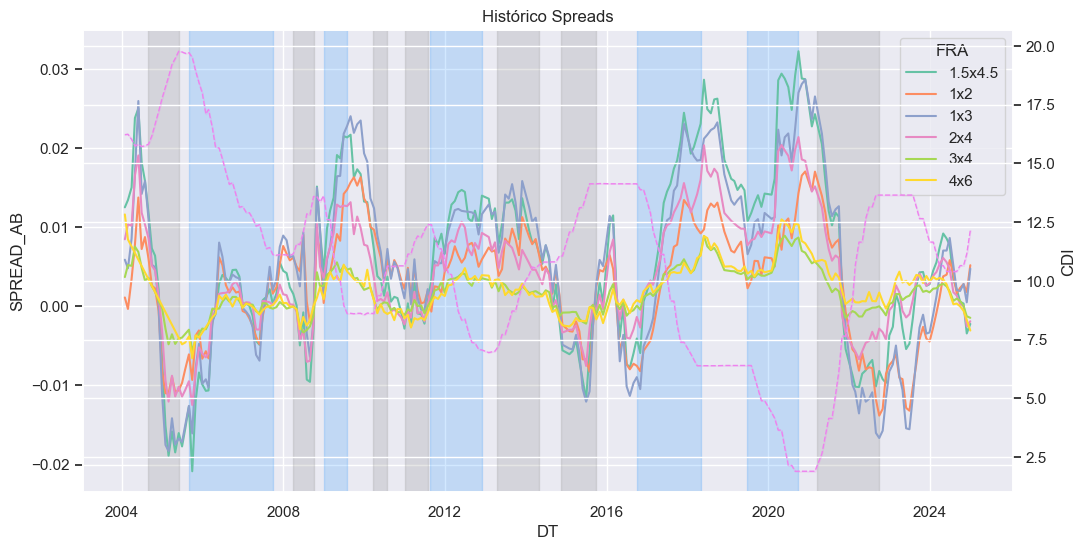

In [6]:
df = df.sort_values(by=['DT','FRA'])
df_grafico = df[df['FRA'].isin(lista_reduzida)]
df_grafico = df_grafico[df_grafico.FL_FIM_MES == 1]
#df_grafico = df_grafico[df_grafico.DT >= datetime(2008,12,30)]

sns.set(style="darkgrid", palette="Set2")
ax1 = sns.lineplot(x='DT', y='SPREAD_AB', data=df_grafico, hue='FRA')
ax2 = ax1.twinx()
ax1.axvspan(datetime(2004,8,30),datetime(2005,5,30), color="grey", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2008,3,31),datetime(2008,9,30), color="grey", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2010,3,19),datetime(2010,7,30), color="grey", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2011,1,2),    datetime(2011,7,30), color="grey", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2013,4,18),    datetime(2014,4,30), color="grey", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2014,11,15), datetime(2015,9,30), color="grey", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2021,3,16),    datetime(2022,9,30), color="grey", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2005,8,30),datetime(2007,9,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2009,1,5),datetime(2009,7,31), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2011,8,20),datetime(2012,11,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2016,9,30), datetime(2018,4,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2019,6,22),datetime(2020,9,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
ax2 = sns.lineplot(x='DT', y='CDI', data=df_grafico, color='violet',linestyle='--',linewidth=1)
ax1.set(title='Histórico Spreads')
plot.show()